In [1]:
from config import *
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

## Load in Sample and Pair Data

In [2]:
parent = Table.read('out/parent.fits', unit_parse_strict = 'silent')
pairs = Table.read('out/pairs.fits', unit_parse_strict = 'silent')

z = np.asarray(parent['Z'])
logM = np.asarray(parent['logmstar'])

## Create Control Pool

In [3]:
# Control pool consists of galaxies that are in the sample and isolated
ctrl_pool = np.where(parent['in_sample'] & parent['isolated'])[0]

print(f'Control pool size: {len(ctrl_pool)} rows')

Control pool size: 36201 rows


## Match Controls to Pairs

In [4]:
def match_controls(k, ctrl_pool, z, logM, n_ctrl = N_CTRL, dz = DZ_TOL, dm = DLOGM_TOL):
    """
    Match control galaxies for a given primary galaxy based on redshift and stellar mass.
    
    Parameters
    ----------
    k : int
        Index of the primary galaxy in the parent table.
    ctrl_pool : array
        Indices of the potential control galaxies in the parent table.
    z : array
        Redshift values of the galaxies in the parent table.
    logM : array
        Logarithm of stellar mass values of the galaxies in the parent table.
    n_ctrl : int
        Number of control galaxies to match.
    dz : float
        Tolerance for redshift matching.
    dm : float
        Tolerance for stellar mass matching.
    
    Returns
    -------
    ctrl_sample : array
        Indices of the matched control galaxies in the parent table.
    """

    # Filter the control pool based on redshift and stellar mass tolerances
    ctrl = (np.abs(z[ctrl_pool] - z[k]) <= dz) & (np.abs(logM[ctrl_pool] - logM[k]) <= dm)
    ctrl_candidates = ctrl_pool[ctrl]

    # If there are not enough candidates, return None
    if len(ctrl_candidates) < n_ctrl:
        return None

    # Calculate the distance metric for the candidates
    d = np.hypot((z[ctrl_candidates] - z[k]) / dz, (logM[ctrl_candidates] - logM[k]) / dm)

    # Select the closest n_ctrl candidates based on the distance metric
    ctrl_samples = ctrl_candidates[np.argsort(d)[:n_ctrl]]

    return ctrl_samples

In [5]:
# Match controls for every pair, using -1 as a placeholder when too few controls qualify
ctrl_indices = np.full((len(pairs), N_CTRL), -1, dtype = int)
ctrl_cataids = np.full((len(pairs), N_CTRL), -1, dtype = np.array(parent['CATAID']).dtype)

for row, k in enumerate(pairs['primary_index']):
    ctrl_samples = match_controls(k, ctrl_pool, z, logM)
    if ctrl_samples is not None:
        ctrl_indices[row] = ctrl_samples
        ctrl_cataids[row] = parent['CATAID'][ctrl_samples]

# Save the control indices and CATAIDs to the pairs table
pairs['control_index'] = ctrl_indices
pairs['control_CATAIDs'] = ctrl_cataids
pairs.write('out/pairs.fits', overwrite = True)

print(f'Number of pairs with matched controls: {np.sum(ctrl_indices[:, 0] != -1)} rows')

Number of pairs with matched controls: 3132 rows


## Diagnostic Plots

In [6]:
# Global plot style
plt.rcParams.update({
    'axes.linewidth': 2.0,
    'axes.labelsize': 14,
    'axes.labelweight': 'normal',
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 4,
    'ytick.minor.size': 4,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12})

# Method to bold the tick labels
def bold_ticks(*axes):
    for ax in axes:
        labels = (ax.get_xticklabels() + ax.get_yticklabels()
            + ax.get_xticklabels(minor = True) + ax.get_yticklabels(minor = True))

        for label in labels:
            label.set_fontweight('bold')

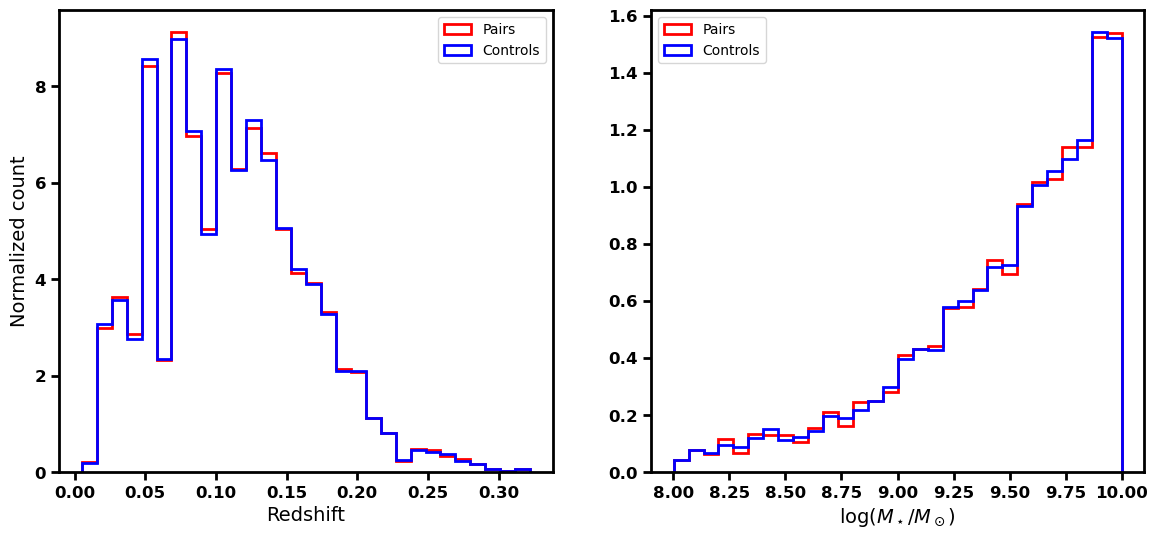

In [7]:
# Plot redshift and mass distributions of the pair primaries and their matched controls
matched = ctrl_indices[:, 0] != -1
pair_index = np.asarray(pairs['primary_index'][matched])
ctrl_index = ctrl_indices[matched].ravel()

fig, axes = plt.subplots(1, 2, figsize = (14, 6))

z_bins = np.histogram_bin_edges(np.concatenate([z[pair_index], z[ctrl_index]]), bins = 30)
axes[0].hist(z[pair_index], bins = z_bins, density = True, histtype = 'step', linewidth = 2, color = 'red', label = 'Pairs')
axes[0].hist(z[ctrl_index], bins = z_bins, density = True, histtype = 'step', linewidth = 2, color = 'blue', label = 'Controls')
axes[0].set_xlabel('Redshift')

logM_bins = np.histogram_bin_edges(np.concatenate([logM[pair_index], logM[ctrl_index]]), bins = 30)
axes[1].hist(logM[pair_index], bins = logM_bins, density = True, histtype = 'step', linewidth = 2, color = 'red', label = 'Pairs')
axes[1].hist(logM[ctrl_index], bins = logM_bins, density = True, histtype = 'step', linewidth = 2, color = 'blue', label = 'Controls')
axes[1].set_xlabel(r'log($M_\star$/$M_\odot$)')

axes[0].set_ylabel('Normalized count')
axes[0].legend()
axes[1].legend()

bold_ticks(*axes)

plt.savefig("figs/control_distributions.pdf", format = "pdf", bbox_inches = "tight")
plt.savefig("figs/control_distributions.png", format = "png", bbox_inches = "tight")

plt.show()